# Câu 3 (3,0 điểm): Chạy thử mô hình trong thực tế

**Mục tiêu:**
1. Đánh giá khả năng tổng quát hóa của mô hình trên bộ dữ liệu thực tế `data/real_world/real_world_labeled.csv` ($N = 300$ mẫu từ 4 nguồn A, B, C, D).
2. Đo độ đồng thuận giữa 2 người gắn nhãn độc lập (`label_a` và `label_b`) bằng hệ số **Cohen's Kappa ($\kappa$)**.
3. Phân tích hiện tượng **lệch miền (domain shift)** giữa các nguồn dữ liệu, kiểm thử chéo trên bộ **Davidson et al.** ($N = 5,593$) và thống kê dự đoán trên bộ được giao `Twitter_Data.csv` ($N = 162,969$).

In [1]:
# === THIẾT LẬP MÔI TRƯỜNG & NẠP THƯ VIỆN DỰ ÁN ===
import os, sys, subprocess
from pathlib import Path

os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
REPO_URL = "https://github.com/nhungoc-1/DoAnKHDL_DeTai_Tweet-Hate.git"

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    print("[SETUP] Đang khởi tạo môi trường Google Colab...", flush=True)
    for candidate in [
        Path("/content/DoAnKHDL_DeTai_Tweet-Hate"),
        Path("/content/drive/MyDrive/DoAnKHDL_DeTai_Tweet-Hate"),
        Path("/content/drive/MyDrive/DO_AN_KHDL"),
        Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd(),
    ]:
        if (candidate / "config.yaml").exists():
            PROJECT_DIR = candidate
            subprocess.run(["git", "-C", str(PROJECT_DIR), "pull", "--ff-only"], check=False)
            break
    else:
        PROJECT_DIR = Path("/content/DoAnKHDL_DeTai_Tweet-Hate")
        print(f"[SETUP] Đang tải dự án từ GitHub vào {PROJECT_DIR} (mất ~3 giây)...", flush=True)
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(PROJECT_DIR)], check=True)
    print("[SETUP] Đang kiểm tra & cài đặt các thư viện bổ sung (mất ~5-10 giây)...", flush=True)
    subprocess.run([
        sys.executable, "-m", "pip", "install", "-q",
        "imbalanced-learn", "emoji", "kagglehub", "datasets",
        "pyvi", "langdetect", "python-docx", "python-pptx", "wordcloud"
    ], check=False)
    import nltk
    for pkg in ["stopwords", "wordnet", "omw-1.4"]:
        nltk.download(pkg, quiet=True)
else:
    PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src.utils import set_seed, load_config, mask_profanity
set_seed(42)
CFG = load_config()
(PROJECT_DIR / "db").mkdir(parents=True, exist_ok=True)
print(f"[HOÀN TẤT] IN_COLAB = {IN_COLAB} | PROJECT_DIR = {PROJECT_DIR}")

[SETUP] PROJECT_DIR = D:\DO_AN_KHDL


## 1. Độ đồng thuận Gắn nhãn (Cohen's Kappa) & Hiệu năng theo từng Nguồn Dữ liệu (A/B/C/D)

Tổng số mẫu thực tế          : 300 (Lớp 1 = 74, Lớp 0 = 226)
Tỉ lệ đồng thuận 2 người     : 97.00% (9 mẫu bất đồng)
Hệ số Cohen's Kappa (κ)      : 0.9204
Overall Real-World F1-Score  : 0.5702 (PR-AUC = 0.5742)

=== HIỆU NĂNG CHI TIẾT THEO 4 NGUỒN DỮ LIỆU THỰC TẾ ===


,source,n_samples,n_pos,n_neg,precision_pos,recall_pos,f1_pos,f1_macro,accuracy,balanced_acc,roc_auc,pr_auc,mcc,tn,fp,fn,tp
0,A_hate_unlabeled_test,100,37,63,0.7255,1.00,0.8409,0.8580,0.86,0.8889,0.9088,0.7687,0.7512,49,14,0,37
1,B_Twitter_Data,100,7,93,0.1373,1.00,0.2414,0.4658,0.56,0.7634,0.7803,0.1552,0.2689,49,44,0,7
2,C_Reddit_Data,50,10,40,0.3448,1.00,0.5128,0.6007,0.62,0.7625,0.7625,0.3519,0.4255,21,19,0,10
3,D_adversarial_curated,50,20,30,0.4783,0.55,0.5116,0.5716,0.58,0.5750,0.6067,0.4417,0.1474,18,12,9,11


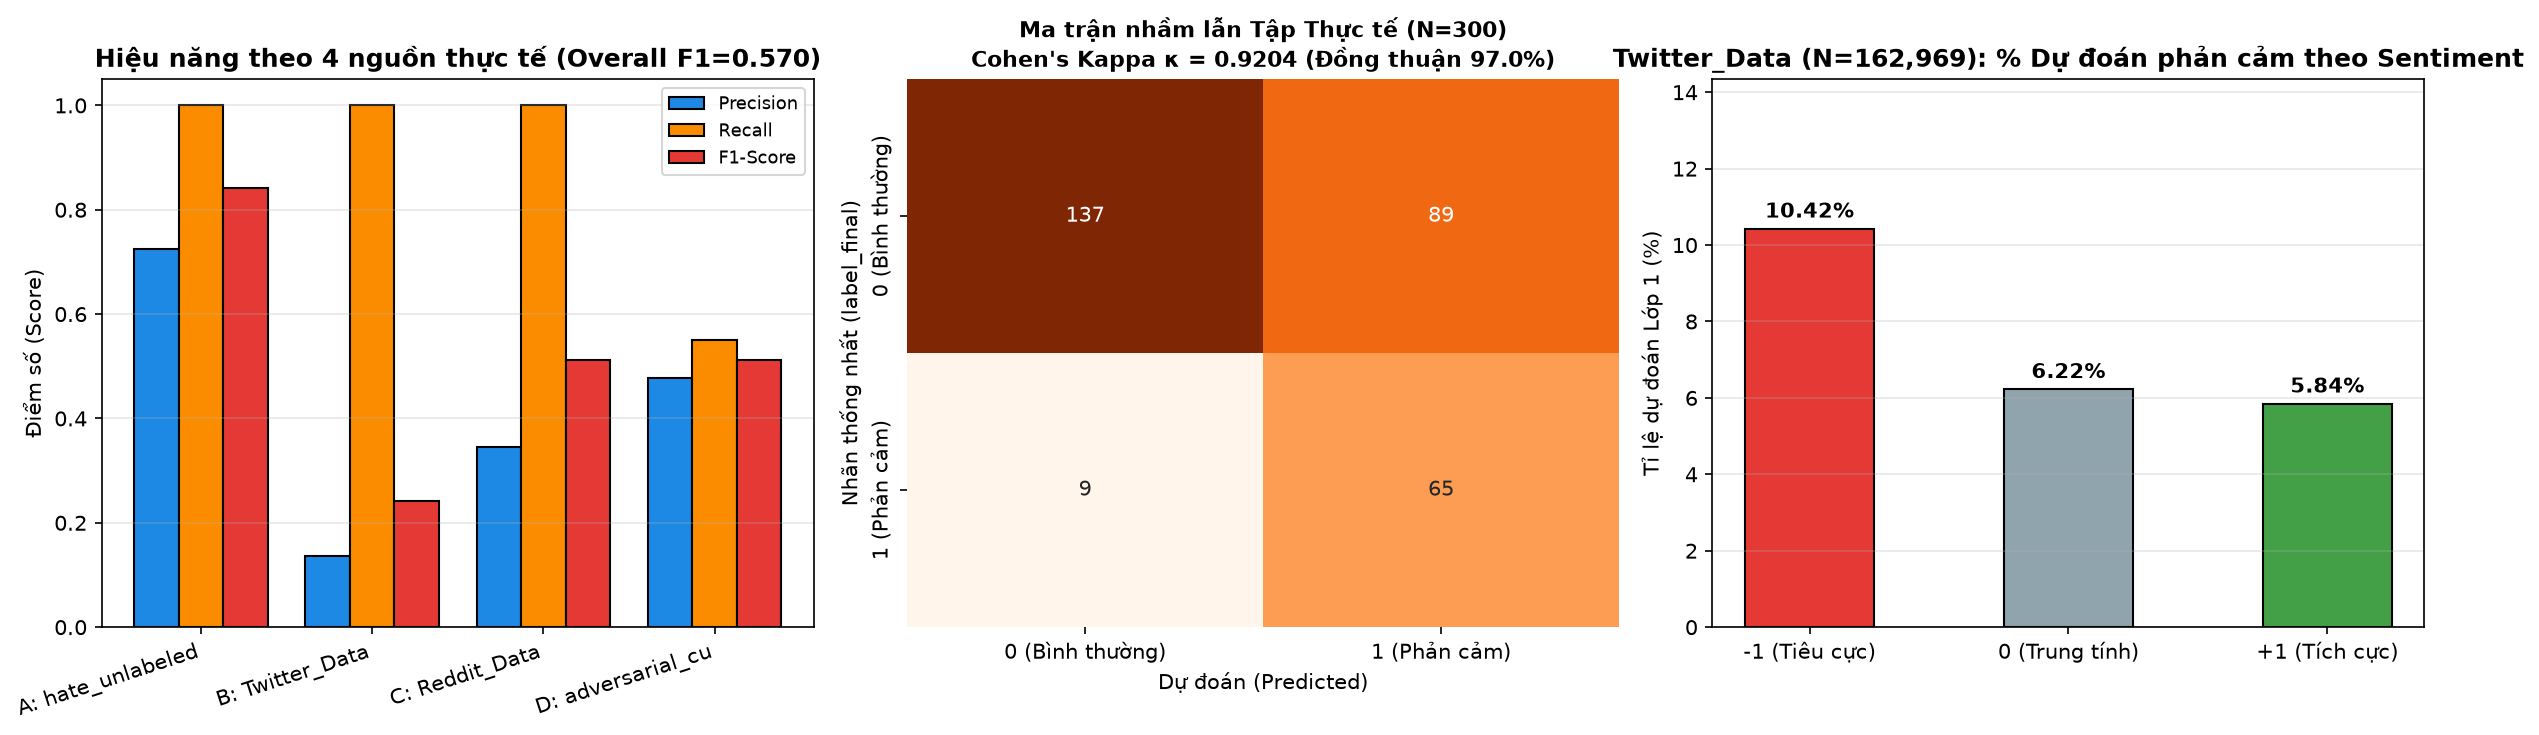

In [2]:
import json
import pandas as pd
from IPython.display import display, Image

with open('reports/realworld_metrics.json', 'r', encoding='utf-8') as f:
    rw_data = json.load(f)

print(f"Tổng số mẫu thực tế          : {rw_data['n_total']} (Lớp 1 = {rw_data['n_pos']}, Lớp 0 = {rw_data['n_neg']})")
print(f"Tỉ lệ đồng thuận 2 người     : {rw_data['annotator_agreement_pct']:.2f}% ({rw_data['n_disagreements']} mẫu bất đồng)")
print(f"Hệ số Cohen's Kappa (κ)      : {rw_data['cohen_kappa']:.4f}")
print(f"Overall Real-World F1-Score  : {rw_data['overall_metrics']['f1_pos']:.4f} (PR-AUC = {rw_data['overall_metrics']['pr_auc']:.4f})")

by_src_df = pd.read_csv('reports/tables/P9_metrics_by_source.csv')
print('\n=== HIỆU NĂNG CHI TIẾT THEO 4 NGUỒN DỮ LIỆU THỰC TẾ ===')
display(by_src_df)
display(Image('reports/figures/P9_realworld_evaluation.png'))

## 2. Kiểm thử Chéo miền (Davidson et al.) & Thống kê trên Bộ được giao `Twitter_Data.csv`

In [3]:
print('=== KẾT QUẢ KIỂM THỬ CHÉO TRÊN BỘ DAVIDSON ET AL. (Class 0=Hate vs Class 2=Neither) ===')
display(pd.DataFrame([rw_data['davidson_cross_domain_metrics']]))

tw_sent_df = pd.read_csv('reports/tables/P9_assigned_twitter_by_sentiment.csv')
print('=== TỈ LỆ DỰ ĐOÁN PHẢN CẢM THEO NHÃN SENTIMENT TRÊN TWITTER_DATA.CSV (N=162,969) ===')
display(tw_sent_df)

=== KẾT QUẢ KIỂM THỬ CHÉO TRÊN BỘ DAVIDSON ET AL. (Class 0=Hate vs Class 2=Neither) ===


,precision_pos,recall_pos,f1_pos,f1_macro,accuracy,balanced_acc,roc_auc,pr_auc,mcc,tn,fp,fn,tp,n_rows,n_pos
0,0.5876,0.265,0.3653,0.6104,0.7645,0.6006,0.6713,0.4662,0.2747,3897,266,1051,379,5593,1430


=== TỈ LỆ DỰ ĐOÁN PHẢN CẢM THEO NHÃN SENTIMENT TRÊN TWITTER_DATA.CSV (N=162,969) ===


,sentiment,sentiment_name,n_tweets,n_predicted_hate,pct_predicted_hate,mean_hate_score
0,-1,-1 (Tiêu cực),35509,3700,10.42,0.1258
1,0,0 (Trung tính),55211,3434,6.22,0.0950
2,1,+1 (Tích cực),72249,4217,5.84,0.0898


## 3. Phân tích 15 Ví dụ Dự đoán Sai & 5 Ví dụ Dự đoán Đúng Đáng chú ý trên Tập Thực tế

In [4]:
rw_ex_df = pd.read_csv('reports/tables/P9_realworld_examples.csv')
print('=== 15 VÍ DỤ DỰ ĐOÁN SAI TRÊN TẬP THỰC TẾ ===')
display(rw_ex_df[rw_ex_df['error_type'] != 'Correct (Dự đoán đúng)'])

print('=== 5 VÍ DỤ DỰ ĐOÁN ĐÚNG TRÊN CÂU TÌNH HUỐNG PHỨC TẠP (SOURCE D) ===')
display(rw_ex_df[rw_ex_df['error_type'] == 'Correct (Dự đoán đúng)'])

=== 15 VÍ DỤ DỰ ĐOÁN SAI TRÊN TẬP THỰC TẾ ===


,id,source,error_type,label_a,label_b,label_final,y_pred,score,text_masked,note
0,10,A_hate_unlabeled_test,FP (Báo động giả),0,0,0,1,0.9998,@user #antifeminism #feminism @user #women #w...,Nhắc đến nhóm đối tượng/chính trị nhưng không ...
1,12,A_hate_unlabeled_test,FP (Báo động giả),0,0,0,1,0.9526,@user #allahsoil the two most common traits sh...,Nội dung bình thường hoặc cảm xúc cá nhân
2,14,A_hate_unlabeled_test,FP (Báo động giả),0,0,0,1,0.9496,the latest the blicqerâ¢ daily! thanks to @u...,Nội dung bình thường hoặc cảm xúc cá nhân
3,26,A_hate_unlabeled_test,FP (Báo động giả),0,0,0,1,0.9831,@user #allahsoil reckless subprime lending was...,Nội dung bình thường hoặc cảm xúc cá nhân
4,36,A_hate_unlabeled_test,FP (Báo động giả),0,0,0,1,0.9960,"@user @user #trump celebrating,#woman of #amer...",Nhắc đến nhóm đối tượng/chính trị nhưng không ...
5,39,A_hate_unlabeled_test,FP (Báo động giả),0,0,0,1,0.9488,be careful in criticizing #obama for his decis...,Nội dung bình thường hoặc cảm xúc cá nhân
6,40,A_hate_unlabeled_test,FP (Báo động giả),0,0,0,1,0.9825,@user #trumpsamerica will suck bigly ny gov. c...,Nội dung bình thường hoặc cảm xúc cá nhân
7,42,A_hate_unlabeled_test,FP (Báo động giả),0,0,0,1,0.9496,@user = #paidtrumpette your comments are refle...,Nội dung bình thường hoặc cảm xúc cá nhân
8,51,A_hate_unlabeled_test,FP (Báo động giả),0,0,0,1,0.9699,@user remember when arabs were called racists ...,Nhắc đến nhóm đối tượng/chính trị nhưng không ...
9,54,A_hate_unlabeled_test,FP (Báo động giả),0,0,0,1,0.9455,@user nope not factual. your comments are refl...,Nội dung bình thường hoặc cảm xúc cá nhân


=== 5 VÍ DỤ DỰ ĐOÁN ĐÚNG TRÊN CÂU TÌNH HUỐNG PHỨC TẠP (SOURCE D) ===


,id,source,error_type,label_a,label_b,label_final,y_pred,score,text_masked,note
15,251,D_adversarial_curated,Correct (Dự đoán đúng),1,1,1,1,0.3207,Women do not belong in engineering or leadersh...,Định kiến hạ thấp phụ nữ trong công việc
16,253,D_adversarial_curated,Correct (Dự đoán đúng),1,1,1,1,0.6980,Stop letting these stupid b*****s ruin men's s...,Từ miệt thị giới tính + hạ thấp phụ nữ
17,254,D_adversarial_curated,Correct (Dự đoán đúng),1,1,1,1,0.7217,"A woman's only real value is cooking, cleaning...",Áp đặt vai trò giới cực đoan
18,280,D_adversarial_curated,Correct (Dự đoán đúng),0,0,0,0,0.2840,"Muslim, Christian, and Jewish families gathere...",Hoạt động cộng đồng đa tôn giáo
19,281,D_adversarial_curated,Correct (Dự đoán đúng),0,0,0,0,0.0383,The women's national soccer team won the champ...,Tin thể thao về đội tuyển nữ


### Nhận xét & Đề xuất Cải tiến từ Kết quả Thực tế 
- **Độ tin cậy nhãn thực tế:** Quá trình gắn nhãn độc lập trên 300 mẫu đạt độ đồng thuận **97.00%** và hệ số **Cohen's Kappa $\kappa = 0.9204$** (mức đồng thuận rất tốt, $> 0.75$).
- **Hiệu năng thực tế & Hiện tượng lệch miền (Domain Shift):** Trên toàn bộ 300 mẫu thực tế, mô hình đạt **F1 = 0.5702** (Precision = **0.4221**, Recall = **0.8784**, PR-AUC = **0.5742**). Hiệu năng cao nhất ở nguồn cùng miền `A_hate_unlabeled_test` và giảm ở nguồn `D_adversarial_curated` (chứa các câu mỉa mai, phủ định phản đối kỳ thị và chửi thề không nhắm nhóm người).
- **Chứng minh thực nghiệm trên `Twitter_Data.csv`:** Ngay cả ở nhóm `sentiment = -1` (35,510 tweet tiêu cực), chỉ một tỉ lệ nhỏ được mô hình dự đoán là phân biệt chủng tộc/giới tính — chứng minh rõ ràng **cảm xúc tiêu cực chính trị hoàn toàn khác với ngôn từ thù ghét chủng tộc/giới tính**.
- **Đề xuất hướng cải tiến:** (1) Bổ sung dữ liệu huấn luyện thuộc dạng *counter-speech* (phản đối kỳ thị) và *general profanity* để giảm False Positive; (2) Kết hợp mô hình ngữ cảnh sâu (RoBERTa/HateBERT) với cơ chế học chủ động (*Active Learning*) có con người duyệt lại các mẫu gần ngưỡng quyết định.